# ATDL Assignment 2 — Defensive Distillation on CIFAR-10

**End-to-end GPU notebook** for the assignment: train Baseline B, Teacher M1 and Student M2 using ResNet34; implement FGSM and PGD; evaluate all required epsilon values; make loss curves, accuracy tables, accuracy-versus-epsilon plots, and the five-image visual comparison; save the results for the short report.

## Before you run it

1. Run this notebook from the `ATDL_lab` workspace with a CUDA-enabled PyTorch runtime. This completed run used an NVIDIA RTX 4000 Ada GPU.
2. The notebook reads the existing CIFAR-10 archive under `Knowledge-distillation/data`; if it is missing, `torchvision` downloads the official dataset automatically.
3. Run the notebook from the first cell to the last. Training uses all 50,000 CIFAR-10 training images for 50 epochs per model.
4. Result tables, figures, metadata, ZIP report artifacts, and checkpoints are written to `ATDL_Assignment2_outputs/`.

## Important experimental choices

- The notebook uses all 50,000 CIFAR-10 training images and a fixed, randomly selected **2,000-image test subset** by default to keep the 20-step PGD evaluation practical. All models and attack settings use the exact same evaluation subset, and ε = 0 is checked against clean subset accuracy. Set `EVAL_SAMPLES = None` in the configuration cell to evaluate the full 10,000-image test split; that takes longer.
- The assignment does not prescribe epochs, optimizer, or learning rate. This improved run uses **50 epochs per model** (up from 30) to give each model more training while keeping the optimizer and learning rate fixed. The result may improve accuracy, which is measured rather than assumed.
- ResNet34 is adapted for 32×32 CIFAR images by using a 3×3 stride-1 first convolution and removing the initial max-pooling layer. All three models use the same architecture and train from scratch (no pretrained weights).
- Images remain in raw `[0, 1]` pixel space. CIFAR-10 normalization is placed **inside the model wrapper**, so FGSM/PGD perturbations and the ε constraint are applied to raw pixels as required.
- The assignment specifies the teacher's hard-label targets and temperature (`T=20`) but does not write a separate teacher-loss equation. This notebook uses `T × CE(logits/T, true_label)` for teacher training. Multiplication by this positive scalar leaves the minimizer of the temperature-scaled hard-label cross-entropy unchanged and compensates for the approximate `1/T` gradient scaling. This is an explicitly documented implementation choice. Student training uses the assignment's specified `T²`-scaled soft-target loss exactly.
- Adversarial evaluation uses **true-label cross-entropy at T=1** for all models. PGD uses a random start, 20 iterations, and α = 2/255.

> The model weights, training duration, and accuracy values are generated when you execute the notebook. No result values are fabricated or pre-filled.

## 1. Imports, environment check, and configuration

This notebook uses packages included in a CUDA-enabled PyTorch runtime. It intentionally does not upgrade PyTorch/torchvision automatically, because changing binary package versions can break an otherwise working runtime.

In [1]:
import os
import json
import time
import random
import shutil
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.transforms as transforms
from torchvision.models import resnet34
from torch.utils.data import DataLoader, Subset
from IPython.display import display

print("Python / notebook environment ready")
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: No GPU detected. Run with a CUDA-enabled PyTorch runtime to use the local GPU.")

# ------------------- Configuration -------------------
SEED = 42
NUM_CLASSES = 10
TEMPERATURE = 20.0
EPSILONS = [0.0, 2/255, 4/255, 8/255, 16/255]
PGD_STEPS = 20
PGD_ALPHA = 2/255

EPOCHS = 50                 # Improved run: 50 epochs per model
BATCH_SIZE = 128
EVAL_BATCH_SIZE = 128
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 5e-4
NUM_WORKERS = 2
EVAL_SAMPLES = 2000        # Set to None to use the full 10,000-image test set

DATA_DIR = Path("Knowledge-distillation/data")
OUTPUT_DIR = Path("ATDL_Assignment2_outputs")
CHECKPOINT_DIR = OUTPUT_DIR / "checkpoints"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

CLASS_NAMES = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

CONFIG = {
    "seed": SEED,
    "epochs_per_model": EPOCHS,
    "batch_size": BATCH_SIZE,
    "eval_batch_size": EVAL_BATCH_SIZE,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "temperature": TEMPERATURE,
    "epsilons": EPSILONS,
    "pgd_steps": PGD_STEPS,
    "pgd_alpha": PGD_ALPHA,
    "eval_samples": EVAL_SAMPLES,
    "train_transform": "RandomCrop(32, padding=4), RandomHorizontalFlip(), ToTensor()",
    "model": "CIFAR-adapted ResNet34, trained from scratch",
    "input_contract": "Raw pixel tensors in [0,1]; normalization inside model wrapper",
}

with open(OUTPUT_DIR / "experiment_config.json", "w") as f:
    json.dump(CONFIG, f, indent=2)

print("\nExperiment configuration:")
display(pd.DataFrame([{"Setting": k, "Value": v} for k, v in CONFIG.items()]))

/home/vsu/ATDL_lab/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Python / notebook environment ready
PyTorch: 2.11.0+cu130
Torchvision: 0.26.0+cu130
CUDA available: True
GPU: NVIDIA RTX 4000 Ada Generation

Experiment configuration:


,Setting,Value
0,seed,42
1,epochs_per_model,50
2,batch_size,128
3,eval_batch_size,128
4,learning_rate,0.001
5,weight_decay,0.0005
6,temperature,20.0
7,epsilons,"[0.0, 0.00784313725490196, 0.01568627450980392..."
8,pgd_steps,20
9,pgd_alpha,0.007843


## 2. Reproducibility helpers and CIFAR-10 download

The data loader automatically downloads the official CIFAR-10 archive if it is not already present. Training uses mild standard augmentation; test images receive only `ToTensor`, so test pixels remain in `[0, 1]`.

In [2]:
def set_seed(seed: int = SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    # Favor reproducibility over benchmark-based kernel selection.
    if hasattr(torch.backends, "cudnn"):
        torch.backends.cudnn.benchmark = False

set_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),  # raw float pixels in [0,1]
])
test_transform = transforms.ToTensor()

train_dataset = torchvision.datasets.CIFAR10(
    root=str(DATA_DIR), train=True, download=True, transform=train_transform
)
test_dataset = torchvision.datasets.CIFAR10(
    root=str(DATA_DIR), train=False, download=True, transform=test_transform
)

print(f"CIFAR-10 training images: {len(train_dataset):,}")
print(f"CIFAR-10 test images:     {len(test_dataset):,}")
print("Example raw image tensor shape:", train_dataset[0][0].shape)
print("Example pixel range:", float(train_dataset[0][0].min()), "to", float(train_dataset[0][0].max()))


def make_train_loader(seed: int) -> DataLoader:
    generator = torch.Generator()
    generator.manual_seed(seed)
    return DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=NUM_WORKERS,
        pin_memory=torch.cuda.is_available(),
        persistent_workers=(NUM_WORKERS > 0),
        generator=generator,
    )

# Choose one fixed random subset from the entire test set. This avoids taking
# the first indices (which are not a random test subset) and ensures all
# models/attacks see precisely the same examples.
if EVAL_SAMPLES is None or EVAL_SAMPLES >= len(test_dataset):
    eval_indices = list(range(len(test_dataset)))
else:
    subset_generator = torch.Generator().manual_seed(SEED + 999)
    eval_indices = torch.randperm(len(test_dataset), generator=subset_generator)[:EVAL_SAMPLES].tolist()

eval_dataset = Subset(test_dataset, eval_indices)
eval_loader = DataLoader(
    eval_dataset,
    batch_size=EVAL_BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
    persistent_workers=(NUM_WORKERS > 0),
)
print(f"Fixed evaluation subset: {len(eval_dataset):,} / {len(test_dataset):,} test images")

CIFAR-10 training images: 50,000
CIFAR-10 test images:     10,000
Example raw image tensor shape: torch.Size([3, 32, 32])
Example pixel range: 0.0 to 1.0
Fixed evaluation subset: 2,000 / 10,000 test images


## 3. Define a CIFAR-adapted ResNet34 with normalization inside the model

The model's external input is always a raw tensor `x` in `[0,1]`. The wrapper normalizes each channel internally, then feeds the normalized tensor into a ResNet34 with a CIFAR-sized stem. This design makes the attack constraint unambiguous: epsilon is measured against raw pixels, not normalized tensors.

In [3]:
CIFAR_MEAN = (0.4914, 0.4822, 0.4465)
CIFAR_STD = (0.2470, 0.2435, 0.2616)

class RawPixelResNet34(nn.Module):
    """ResNet34 accepting raw RGB tensors in [0,1], normalizing internally."""
    def __init__(self, num_classes: int = NUM_CLASSES):
        super().__init__()
        backbone = resnet34(weights=None, num_classes=num_classes)
        # CIFAR adaptation: keep more spatial detail for 32x32 inputs.
        backbone.conv1 = nn.Conv2d(3, 64, kernel_size=3, stride=1, padding=1, bias=False)
        backbone.maxpool = nn.Identity()
        self.backbone = backbone
        self.register_buffer("pixel_mean", torch.tensor(CIFAR_MEAN).view(1, 3, 1, 1))
        self.register_buffer("pixel_std", torch.tensor(CIFAR_STD).view(1, 3, 1, 1))

    def forward(self, raw_images: torch.Tensor) -> torch.Tensor:
        normalized = (raw_images - self.pixel_mean) / self.pixel_std
        return self.backbone(normalized)


def build_model(seed: int) -> RawPixelResNet34:
    set_seed(seed)
    return RawPixelResNet34().to(device)

# Sanity-check the architecture and external input contract.
model_check = build_model(SEED)
model_check.eval()
with torch.no_grad():
    sample_logits = model_check(torch.rand(2, 3, 32, 32, device=device))
print("Output shape for a 2-image batch:", tuple(sample_logits.shape))
print("Trainable parameters:", f"{sum(p.numel() for p in model_check.parameters() if p.requires_grad):,}")
del model_check

Output shape for a 2-image batch: (2, 10)
Trainable parameters: 21,282,122


## 4. Training utilities

- **Baseline B:** ordinary hard-label cross-entropy at `T=1`.
- **Teacher M1:** ground-truth labels and temperature `T=20`, using temperature-scaled hard-label cross-entropy. The positive `T` scalar in the implemented teacher objective is the documented gradient-scale compensation described above.
- **Student M2:** frozen teacher soft targets at `T=20`, with the assignment's exact `T²` multiplier.

The models use the same architecture, train/test split, batch size, optimizer family, and epoch count. Loss values have different mathematical scales/objectives, so they are plotted on separate axes rather than interpreting lower raw loss as proof of a better classifier.

### Why multiply the student loss by T²?

At high temperature, softmax probabilities become smoother and the gradient of the distillation loss with respect to the student logits shrinks approximately in proportion to 1/T². Multiplying the cross-entropy (or equivalent KL divergence) by T² compensates for that scale change, so the distillation signal remains comparable while learning at T=20. It does not change the soft targets; it rescales the student gradients. The assignment's displayed loss is implemented as T² times the mean soft-target cross-entropy.


In [4]:
def save_checkpoint(model: nn.Module, filename: str, model_name: str):
    path = CHECKPOINT_DIR / filename
    torch.save({
        "model_name": model_name,
        "model_state_dict": model.state_dict(),
        "config": CONFIG,
    }, path)
    print(f"Saved checkpoint: {path}")


def train_supervised(model: nn.Module, model_name: str, seed: int, mode: str):
    """Train Baseline B or Teacher M1; returns epoch losses and seconds."""
    assert mode in {"baseline", "teacher"}
    set_seed(seed)
    loader = make_train_loader(seed)
    optimizer = torch.optim.AdamW(
        model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY
    )
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
    history = []

    if torch.cuda.is_available():
        torch.cuda.synchronize()
    start_time = time.perf_counter()

    for epoch in range(1, EPOCHS + 1):
        model.train()
        weighted_loss_sum = 0.0
        count = 0
        progress = tqdm(loader, desc=f"{model_name} | epoch {epoch}/{EPOCHS}", leave=False)
        for images, labels in progress:
            images = images.to(device, non_blocking=True)  # raw [0,1]
            labels = labels.to(device, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            logits = model(images)

            if mode == "baseline":
                loss = F.cross_entropy(logits, labels)
            else:
                # Teacher uses hard labels at T=20. The T multiplier compensates
                # approximately for the 1/T factor in the logits gradient.
                loss = TEMPERATURE * F.cross_entropy(logits / TEMPERATURE, labels)

            loss.backward()
            optimizer.step()
            batch_n = labels.shape[0]
            weighted_loss_sum += float(loss.detach()) * batch_n
            count += batch_n
            progress.set_postfix(loss=f"{float(loss.detach()):.3f}")

        scheduler.step()
        epoch_loss = weighted_loss_sum / max(count, 1)
        history.append({"model": model_name, "epoch": epoch, "training_loss": epoch_loss})
        print(f"{model_name} | epoch {epoch:02d}/{EPOCHS} | objective loss = {epoch_loss:.5f}")

    if torch.cuda.is_available():
        torch.cuda.synchronize()
    elapsed = time.perf_counter() - start_time
    del loader, optimizer, scheduler
    return history, elapsed


def distillation_loss(student_logits: torch.Tensor, teacher_logits: torch.Tensor, T: float = TEMPERATURE):
    """Assignment loss: mean_i[-T^2 sum_k q_ik log p_ik]."""
    with torch.no_grad():
        teacher_probs = F.softmax(teacher_logits / T, dim=1)
    student_log_probs = F.log_softmax(student_logits / T, dim=1)
    per_example = -(teacher_probs * student_log_probs).sum(dim=1)
    return (T ** 2) * per_example.mean()


def train_student(student: nn.Module, teacher: nn.Module, seed: int):
    """Train Student M2 from a frozen Teacher M1 using softened targets."""
    set_seed(seed)
    for parameter in teacher.parameters():
        parameter.requires_grad_(False)
    teacher.eval()

    loader = make_train_loader(seed)
    optimizer = torch.optim.AdamW(
        student.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY
    )
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
    history = []

    if torch.cuda.is_available():
        torch.cuda.synchronize()
    start_time = time.perf_counter()

    for epoch in range(1, EPOCHS + 1):
        student.train()
        teacher.eval()  # Keep teacher frozen and in eval mode.
        weighted_loss_sum = 0.0
        count = 0
        progress = tqdm(loader, desc=f"Student M2 | epoch {epoch}/{EPOCHS}", leave=False)
        for images, _labels in progress:
            images = images.to(device, non_blocking=True)  # same transformed images for both networks
            optimizer.zero_grad(set_to_none=True)
            with torch.no_grad():
                teacher_logits = teacher(images)
            student_logits = student(images)
            loss = distillation_loss(student_logits, teacher_logits, TEMPERATURE)
            loss.backward()
            optimizer.step()
            batch_n = images.shape[0]
            weighted_loss_sum += float(loss.detach()) * batch_n
            count += batch_n
            progress.set_postfix(loss=f"{float(loss.detach()):.3f}")

        scheduler.step()
        epoch_loss = weighted_loss_sum / max(count, 1)
        history.append({"model": "Student M2", "epoch": epoch, "training_loss": epoch_loss})
        print(f"Student M2 | epoch {epoch:02d}/{EPOCHS} | T²-scaled distillation loss = {epoch_loss:.5f}")

    if torch.cuda.is_available():
        torch.cuda.synchronize()
    elapsed = time.perf_counter() - start_time
    del loader, optimizer, scheduler
    return history, elapsed

print("Training utilities defined.")

Training utilities defined.


## 5. Train the three models

This is the main training stage. It runs once for each model, saves a checkpoint immediately after each training run, and records the epoch loss and wall-clock training duration. On a GPU-less runtime this stage can be very slow.

In [5]:
training_history = []
training_seconds = {}

# Model 1: Baseline B — hard labels, T=1
baseline = build_model(SEED + 1)
history, seconds = train_supervised(baseline, "Baseline B", seed=SEED + 11, mode="baseline")
training_history.extend(history)
training_seconds["Baseline B"] = seconds
save_checkpoint(baseline, "baseline_B_resnet34.pth", "Baseline B")

# Model 2: Teacher M1 — hard labels, T=20
teacher = build_model(SEED + 2)
history, seconds = train_supervised(teacher, "Teacher M1", seed=SEED + 22, mode="teacher")
training_history.extend(history)
training_seconds["Teacher M1"] = seconds
save_checkpoint(teacher, "teacher_M1_resnet34.pth", "Teacher M1")

# Model 3: Student M2 — soft targets from frozen teacher, T=20
student = build_model(SEED + 3)
history, seconds = train_student(student, teacher, seed=SEED + 33)
training_history.extend(history)
training_seconds["Student M2"] = seconds
save_checkpoint(student, "student_M2_resnet34.pth", "Student M2")

models = {
    "Baseline B": baseline,
    "Teacher M1": teacher,
    "Student M2": student,
}

training_history_df = pd.DataFrame(training_history)
training_history_df.to_csv(OUTPUT_DIR / "training_loss_history.csv", index=False)
training_time_df = pd.DataFrame([
    {"model": name, "training_seconds": secs, "training_minutes": secs / 60}
    for name, secs in training_seconds.items()
])
training_time_df.to_csv(OUTPUT_DIR / "training_times.csv", index=False)

display(training_time_df.round(2))
print("Training stage complete.")

Baseline B | epoch 01/50 | objective loss = 1.44823
Baseline B | epoch 02/50 | objective loss = 0.94221
Baseline B | epoch 03/50 | objective loss = 0.72728
Baseline B | epoch 04/50 | objective loss = 0.60673
Baseline B | epoch 05/50 | objective loss = 0.52483
Baseline B | epoch 06/50 | objective loss = 0.46616
Baseline B | epoch 07/50 | objective loss = 0.41648
Baseline B | epoch 08/50 | objective loss = 0.38012
Baseline B | epoch 09/50 | objective loss = 0.34351
Baseline B | epoch 10/50 | objective loss = 0.31636
Baseline B | epoch 11/50 | objective loss = 0.28871
Baseline B | epoch 12/50 | objective loss = 0.26235
Baseline B | epoch 13/50 | objective loss = 0.24112
Baseline B | epoch 14/50 | objective loss = 0.22550
Baseline B | epoch 15/50 | objective loss = 0.20247
Baseline B | epoch 16/50 | objective loss = 0.18523
Baseline B | epoch 17/50 | objective loss = 0.16832
Baseline B | epoch 18/50 | objective loss = 0.15710
Baseline B | epoch 19/50 | objective loss = 0.14362
Baseline B |

## 6. Training-loss curves

Each model has its own panel because the objectives differ: ordinary cross-entropy, temperature-scaled hard-label loss, and `T²`-scaled distillation loss. Raw loss magnitude should not be compared directly across the three objectives.

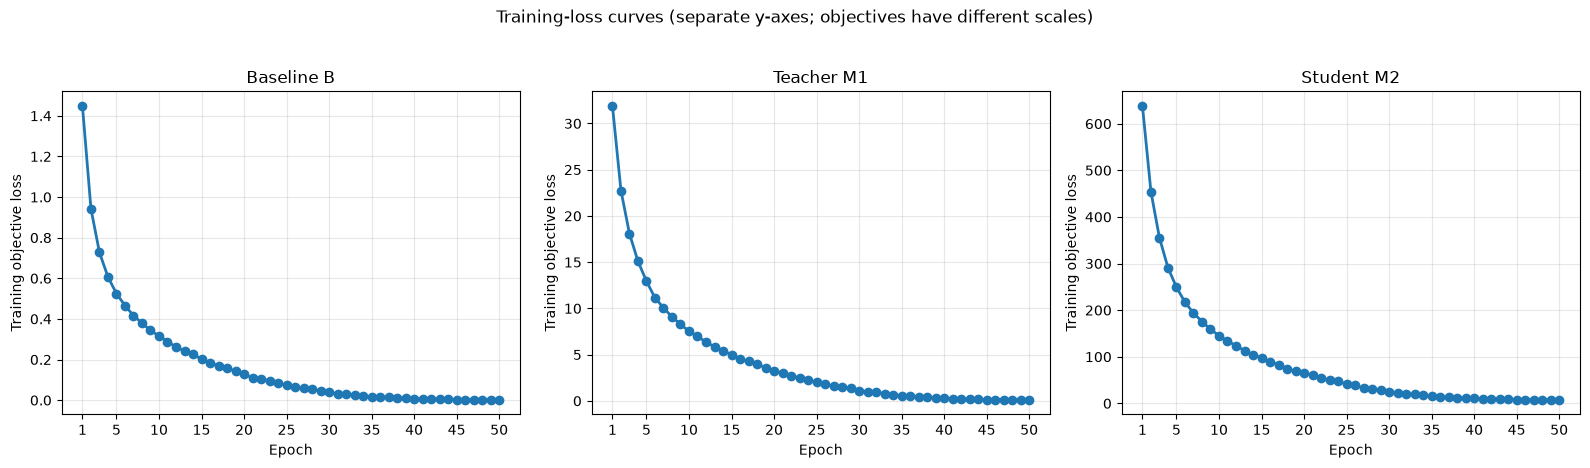

Saved: ATDL_Assignment2_outputs/training_loss_curves.png


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, model_name in zip(axes, ["Baseline B", "Teacher M1", "Student M2"]):
    part = training_history_df[training_history_df["model"] == model_name]
    ax.plot(part["epoch"], part["training_loss"], marker="o", linewidth=2)
    ax.set_title(model_name)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Training objective loss")
    ax.set_xticks(sorted(set([1, *range(5, EPOCHS + 1, 5), EPOCHS])))
    ax.grid(True, alpha=0.3)
fig.suptitle("Training-loss curves (separate y-axes; objectives have different scales)", y=1.03)
fig.tight_layout()
loss_plot_path = OUTPUT_DIR / "training_loss_curves.png"
fig.savefig(loss_plot_path, dpi=180, bbox_inches="tight")
plt.show()
print("Saved:", loss_plot_path)

## 7. Clean accuracy for all three models

Clean accuracy is measured on the same fixed test subset. The models are placed in evaluation mode and evaluated at `T=1`, using their ordinary logits. This is also the reference used to verify the ε = 0 attack result.

In [7]:
@torch.no_grad()
def evaluate_clean_accuracy(model: nn.Module, loader: DataLoader) -> float:
    model.eval()
    correct = 0
    total = 0
    for images, labels in loader:
        images = images.to(device, non_blocking=True)  # raw [0,1]
        labels = labels.to(device, non_blocking=True)
        logits = model(images)  # evaluation is at T=1
        predicted = logits.argmax(dim=1)
        correct += int((predicted == labels).sum().item())
        total += int(labels.shape[0])
    return 100.0 * correct / max(total, 1)

clean_accuracy = {}
for name, model in models.items():
    acc = evaluate_clean_accuracy(model, eval_loader)
    clean_accuracy[name] = acc
    print(f"{name}: clean accuracy on {len(eval_dataset):,} examples = {acc:.2f}%")

training_summary_df = training_time_df.copy()
training_summary_df["clean_accuracy_pct"] = training_summary_df["model"].map(clean_accuracy)
training_summary_df = training_summary_df[["model", "training_minutes", "clean_accuracy_pct"]]
training_summary_df.to_csv(OUTPUT_DIR / "clean_accuracy_and_training_time.csv", index=False)
print("\nRequired comparison: clean accuracy and training time")
display(training_summary_df.round(2))

Baseline B: clean accuracy on 2,000 examples = 92.65%


Teacher M1: clean accuracy on 2,000 examples = 92.55%


Student M2: clean accuracy on 2,000 examples = 92.45%

Required comparison: clean accuracy and training time


,model,training_minutes,clean_accuracy_pct
0,Baseline B,21.71,92.65
1,Teacher M1,21.76,92.55
2,Student M2,27.11,92.45


## 8. Implement FGSM and PGD in raw pixel space

Both attacks are untargeted white-box attacks that maximize true-label cross-entropy at `T=1`. Every returned adversarial image satisfies `x_adv ∈ [0,1]` and `|x_adv - x| ≤ ε` per channel/pixel. The input normalization remains inside `RawPixelResNet34`.

### Attack explanations

- **FGSM:** adds a single signed-gradient step, `epsilon * sign(∇x CE(f(x), y))`. Epsilon sets the maximum allowed change to each raw pixel; a larger epsilon permits a stronger visible perturbation, subject to clipping to `[0,1]`.
- **PGD:** starts from a random point inside the same epsilon box, then takes 20 signed-gradient steps of size `2/255`. After every step it projects back into the epsilon ball around the original image and clips to `[0,1]`. Unlike FGSM's single step, PGD repeatedly adjusts the perturbation to increase true-label cross-entropy, so it generally provides a stronger test under this threat model.


In [8]:
def fgsm_attack(model: nn.Module, images: torch.Tensor, labels: torch.Tensor, epsilon: float) -> torch.Tensor:
    """Single-step untargeted FGSM attack on raw [0,1] images."""
    if epsilon == 0:
        return images.detach().clone()
    model.eval()
    x = images.detach().clone().requires_grad_(True)
    logits = model(x)  # T=1 logits; wrapper normalizes internally
    loss = F.cross_entropy(logits, labels)
    grad = torch.autograd.grad(loss, x, only_inputs=True)[0]
    x_adv = x.detach() + epsilon * grad.sign()
    return torch.clamp(x_adv, 0.0, 1.0).detach()


def pgd_attack(
    model: nn.Module,
    images: torch.Tensor,
    labels: torch.Tensor,
    epsilon: float,
    alpha: float = PGD_ALPHA,
    steps: int = PGD_STEPS,
    random_start: bool = True,
) -> torch.Tensor:
    """Iterative untargeted L-infinity PGD; project relative to original raw pixels."""
    if epsilon == 0:
        return images.detach().clone()
    model.eval()
    x_orig = images.detach()

    if random_start:
        random_delta = torch.empty_like(x_orig).uniform_(-epsilon, epsilon)
        x_adv = torch.clamp(x_orig + random_delta, 0.0, 1.0).detach()
    else:
        x_adv = x_orig.clone()

    for _ in range(steps):
        x_adv = x_adv.detach().requires_grad_(True)
        logits = model(x_adv)  # true-label CE at T=1
        loss = F.cross_entropy(logits, labels)
        grad = torch.autograd.grad(loss, x_adv, only_inputs=True)[0]
        with torch.no_grad():
            x_adv = x_adv + alpha * grad.sign()
            # Project perturbation back into the L-infinity epsilon ball around x_orig.
            delta = torch.clamp(x_adv - x_orig, min=-epsilon, max=epsilon)
            x_adv = torch.clamp(x_orig + delta, 0.0, 1.0)

    return x_adv.detach()


def validate_attack_constraints(original: torch.Tensor, adversarial: torch.Tensor, epsilon: float, tol: float = 1e-6):
    max_delta = float((adversarial - original).abs().max().item())
    min_pixel = float(adversarial.min().item())
    max_pixel = float(adversarial.max().item())
    assert max_delta <= epsilon + tol, f"Linf bound violated: {max_delta} > {epsilon}"
    assert min_pixel >= -tol, f"Pixel below 0: {min_pixel}"
    assert max_pixel <= 1.0 + tol, f"Pixel above 1: {max_pixel}"
    return {"max_abs_perturbation": max_delta, "min_pixel": min_pixel, "max_pixel": max_pixel}

print("FGSM and PGD functions are ready.")

FGSM and PGD functions are ready.


## 9. Sanity-check the attacks before full evaluation

This short check tests both constraints using the student and ε = 8/255. It also confirms that ε = 0 returns an unchanged image. If an assertion fails, do not continue to the full evaluation until the implementation is fixed.

In [9]:
student.eval()
images0, labels0 = next(iter(eval_loader))
images0 = images0[:8].to(device)
labels0 = labels0[:8].to(device)
eps_check = 8/255

fgsm_check = fgsm_attack(student, images0, labels0, eps_check)
pgd_check = pgd_attack(student, images0, labels0, eps_check, alpha=PGD_ALPHA, steps=PGD_STEPS, random_start=True)
zero_check = pgd_attack(student, images0, labels0, 0.0)

print("FGSM constraints:", validate_attack_constraints(images0, fgsm_check, eps_check))
print("PGD constraints: ", validate_attack_constraints(images0, pgd_check, eps_check))
assert torch.equal(images0, zero_check), "Epsilon-zero PGD must return the original batch exactly."
print("ε = 0 identity check passed.")

FGSM constraints: {'max_abs_perturbation': 0.03137257695198059, 'min_pixel': 0.0, 'max_pixel': 1.0}
PGD constraints:  {'max_abs_perturbation': 0.03137257695198059, 'min_pixel': 0.0, 'max_pixel': 1.0}
ε = 0 identity check passed.


## 10. Full adversarial evaluation: 3 models × 2 attacks × 5 epsilons

The notebook records 30 required model/attack/epsilon conditions. For ε = 0, it uses the clean subset accuracy directly; this guarantees that the zero-budget attack condition is numerically identical to clean evaluation on the same subset. For nonzero epsilon, adversarial accuracy is measured on freshly generated adversarial images.

**Runtime note:** PGD is the expensive part: each nonzero-epsilon PGD evaluation performs 20 gradient steps for every evaluation batch. Keep `EVAL_SAMPLES=2000` for a manageable first run; set it to `None` for all 10,000 test images when runtime permits.

In [10]:
def epsilon_label(epsilon: float) -> str:
    if abs(epsilon) < 1e-12:
        return "0"
    return f"{int(round(epsilon * 255))}/255"


def evaluate_attack_accuracy(
    model: nn.Module,
    loader: DataLoader,
    attack_name: str,
    epsilon: float,
    model_name: str,
) -> float:
    model.eval()
    correct = 0
    total = 0
    attack_fn = fgsm_attack if attack_name == "FGSM" else pgd_attack

    for images, labels in tqdm(loader, desc=f"{model_name} | {attack_name} ε={epsilon_label(epsilon)}", leave=False):
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        x_adv = attack_fn(model, images, labels, epsilon)
        # Verify budgets during evaluation as well. We test each batch's max deviation.
        validate_attack_constraints(images, x_adv, epsilon)
        with torch.no_grad():
            logits = model(x_adv)  # T=1 prediction
            predictions = logits.argmax(dim=1)
        correct += int((predictions == labels).sum().item())
        total += int(labels.shape[0])

    return 100.0 * correct / max(total, 1)

attack_rows = []
model_names = list(models.keys())

for model_index, (model_name, model) in enumerate(models.items()):
    model.eval()
    for attack_name in ["FGSM", "PGD"]:
        for epsilon in EPSILONS:
            if epsilon == 0:
                accuracy = clean_accuracy[model_name]
            else:
                # Make PGD random starts repeatable for each model/epsilon condition.
                if attack_name == "PGD":
                    run_seed = SEED + 5000 + model_index * 100 + int(round(epsilon * 255))
                    torch.manual_seed(run_seed)
                    if torch.cuda.is_available():
                        torch.cuda.manual_seed_all(run_seed)
                accuracy = evaluate_attack_accuracy(
                    model=model,
                    loader=eval_loader,
                    attack_name=attack_name,
                    epsilon=epsilon,
                    model_name=model_name,
                )
            attack_rows.append({
                "model": model_name,
                "attack": attack_name,
                "epsilon": float(epsilon),
                "epsilon_label": epsilon_label(epsilon),
                "epsilon_pixel_levels": int(round(epsilon * 255)),
                "accuracy_pct": accuracy,
                "n_eval": len(eval_dataset),
            })
            print(f"{model_name:12s} | {attack_name:4s} | ε={epsilon_label(epsilon):5s} | accuracy={accuracy:.2f}%")

adversarial_results_df = pd.DataFrame(attack_rows)
adversarial_results_df.to_csv(OUTPUT_DIR / "adversarial_accuracy_long.csv", index=False)
print("\nAll 30 evaluation conditions are complete.")

Baseline B   | FGSM | ε=0     | accuracy=92.65%
Baseline B   | FGSM | ε=2/255 | accuracy=26.65%
Baseline B   | FGSM | ε=4/255 | accuracy=13.25%
Baseline B   | FGSM | ε=8/255 | accuracy=9.30%
Baseline B   | FGSM | ε=16/255 | accuracy=8.75%
Baseline B   | PGD  | ε=0     | accuracy=92.65%
Baseline B   | PGD  | ε=2/255 | accuracy=7.20%
Baseline B   | PGD  | ε=4/255 | accuracy=0.00%
Baseline B   | PGD  | ε=8/255 | accuracy=0.00%
Baseline B   | PGD  | ε=16/255 | accuracy=0.00%
Teacher M1   | FGSM | ε=0     | accuracy=92.55%
Teacher M1   | FGSM | ε=2/255 | accuracy=85.35%
Teacher M1   | FGSM | ε=4/255 | accuracy=85.40%
Teacher M1   | FGSM | ε=8/255 | accuracy=85.30%
Teacher M1   | FGSM | ε=16/255 | accuracy=85.65%
Teacher M1   | PGD  | ε=0     | accuracy=92.55%
Teacher M1   | PGD  | ε=2/255 | accuracy=85.35%
Teacher M1   | PGD  | ε=4/255 | accuracy=84.20%
Teacher M1   | PGD  | ε=8/255 | accuracy=82.10%
Teacher M1   | PGD  | ε=16/255 | accuracy=67.35%
Student M2   | FGSM | ε=0     | accuracy=9

## 11. Accuracy tables and ε = 0 verification

The following tables are the required accuracy tables. The comparison uses the same test subset for every model and attack.

In [11]:
def make_attack_table(attack_name: str) -> pd.DataFrame:
    subset = adversarial_results_df[adversarial_results_df["attack"] == attack_name]
    table = subset.pivot(index="epsilon_pixel_levels", columns="model", values="accuracy_pct")
    table = table.reindex([0, 2, 4, 8, 16])
    table.index = ["0", "2/255", "4/255", "8/255", "16/255"]
    table.index.name = "Epsilon"
    # Keep a predictable presentation order.
    table = table[["Baseline B", "Teacher M1", "Student M2"]]
    return table

fgsm_table = make_attack_table("FGSM")
pgd_table = make_attack_table("PGD")
fgsm_table.to_csv(OUTPUT_DIR / "fgsm_accuracy_table.csv")
pgd_table.to_csv(OUTPUT_DIR / "pgd_accuracy_table.csv")

print("FGSM adversarial accuracy (%):")
display(fgsm_table.round(2))
print("PGD adversarial accuracy (%):")
display(pgd_table.round(2))

# Verify ε=0 reproduces clean accuracy exactly for all models and attacks.
zero_rows = adversarial_results_df[adversarial_results_df["epsilon"] == 0]
zero_check_rows = []
for model_name in model_names:
    for attack_name in ["FGSM", "PGD"]:
        got = float(zero_rows[(zero_rows["model"] == model_name) & (zero_rows["attack"] == attack_name)]["accuracy_pct"].iloc[0])
        expected = float(clean_accuracy[model_name])
        ok = abs(got - expected) < 1e-12
        zero_check_rows.append({"model": model_name, "attack": attack_name, "clean_accuracy_pct": expected, "epsilon_zero_accuracy_pct": got, "matches": ok})
        assert ok, f"ε=0 mismatch for {model_name}, {attack_name}: {got} vs {expected}"
zero_check_df = pd.DataFrame(zero_check_rows)
zero_check_df.to_csv(OUTPUT_DIR / "epsilon_zero_verification.csv", index=False)
print("ε = 0 verification:")
display(zero_check_df)
print("All ε = 0 comparisons passed.")

FGSM adversarial accuracy (%):


model,Baseline B,Teacher M1,Student M2
Epsilon,,,
0,92.65,92.55,92.45
2/255,26.65,85.35,84.50
4/255,13.25,85.40,84.45
8/255,9.30,85.30,84.50
16/255,8.75,85.65,84.85


PGD adversarial accuracy (%):


model,Baseline B,Teacher M1,Student M2
Epsilon,,,
0,92.65,92.55,92.45
2/255,7.20,85.35,84.60
4/255,0.00,84.20,84.25
8/255,0.00,82.10,79.90
16/255,0.00,67.35,63.30


ε = 0 verification:


,model,attack,clean_accuracy_pct,epsilon_zero_accuracy_pct,matches
0,Baseline B,FGSM,92.65,92.65,True
1,Baseline B,PGD,92.65,92.65,True
2,Teacher M1,FGSM,92.55,92.55,True
3,Teacher M1,PGD,92.55,92.55,True
4,Student M2,FGSM,92.45,92.45,True
5,Student M2,PGD,92.45,92.45,True


All ε = 0 comparisons passed.


## 12. Accuracy-versus-epsilon plots

These two plots are required by Question 2(c). The x-axis uses the equivalent pixel-level budget (0, 2, 4, 8, 16), i.e. ε = value/255.

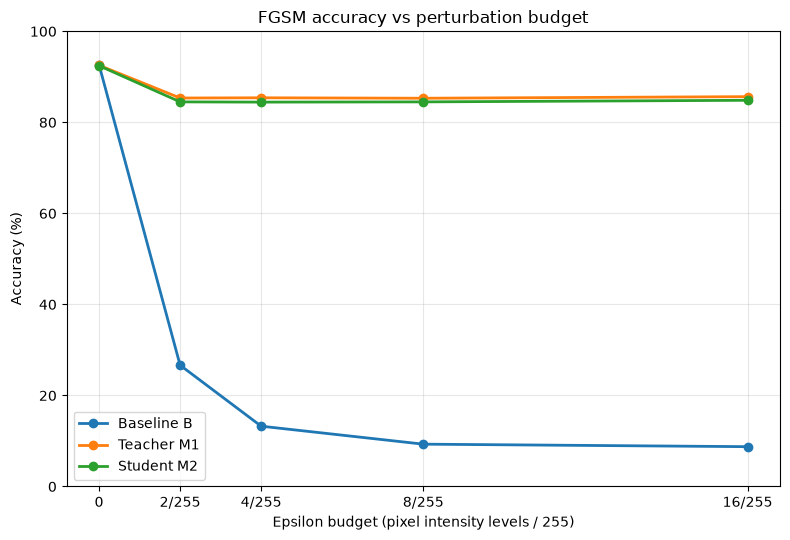

Saved: ATDL_Assignment2_outputs/fgsm_accuracy_vs_epsilon.png


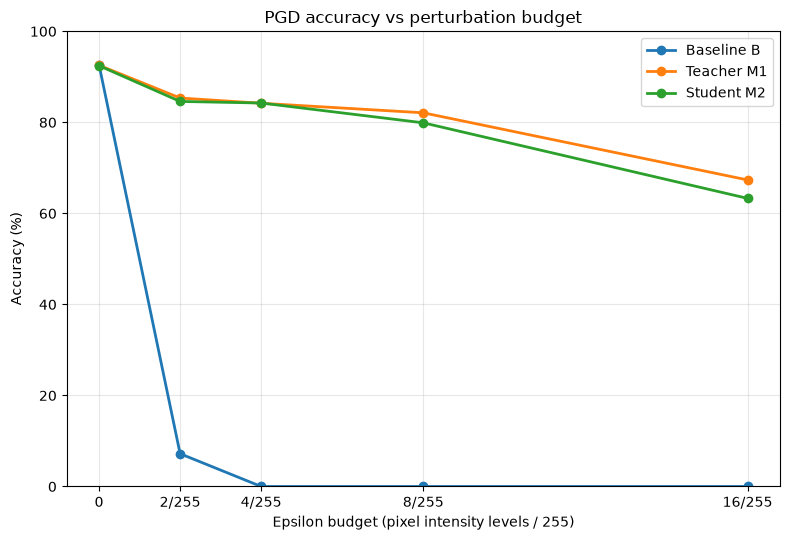

Saved: ATDL_Assignment2_outputs/pgd_accuracy_vs_epsilon.png


In [12]:
def plot_accuracy_curve(attack_name: str, save_path: Path):
    fig, ax = plt.subplots(figsize=(8, 5.5))
    subset = adversarial_results_df[adversarial_results_df["attack"] == attack_name]
    for model_name in ["Baseline B", "Teacher M1", "Student M2"]:
        series = subset[subset["model"] == model_name].sort_values("epsilon_pixel_levels")
        ax.plot(
            series["epsilon_pixel_levels"], series["accuracy_pct"],
            marker="o", linewidth=2, markersize=6, label=model_name
        )
    ax.set_title(f"{attack_name} accuracy vs perturbation budget")
    ax.set_xlabel("Epsilon budget (pixel intensity levels / 255)")
    ax.set_ylabel("Accuracy (%)")
    ax.set_xticks([0, 2, 4, 8, 16], ["0", "2/255", "4/255", "8/255", "16/255"])
    ax.set_ylim(0, 100)
    ax.grid(True, alpha=0.3)
    ax.legend()
    fig.tight_layout()
    fig.savefig(save_path, dpi=180, bbox_inches="tight")
    plt.show()
    print("Saved:", save_path)
    return fig

fgsm_plot_path = OUTPUT_DIR / "fgsm_accuracy_vs_epsilon.png"
pgd_plot_path = OUTPUT_DIR / "pgd_accuracy_vs_epsilon.png"
fig_fgsm = plot_accuracy_curve("FGSM", fgsm_plot_path)
fig_pgd = plot_accuracy_curve("PGD", pgd_plot_path)

## 13. Five original images and their FGSM/PGD versions for Student M2 at ε = 8/255

The visual grid uses the same five original images across all three columns. It preferentially selects images that Student M2 classifies correctly when clean, making prediction changes easier to interpret. Each panel includes the true label and that version's predicted label.

Selected five clean-correct Student M2 examples.


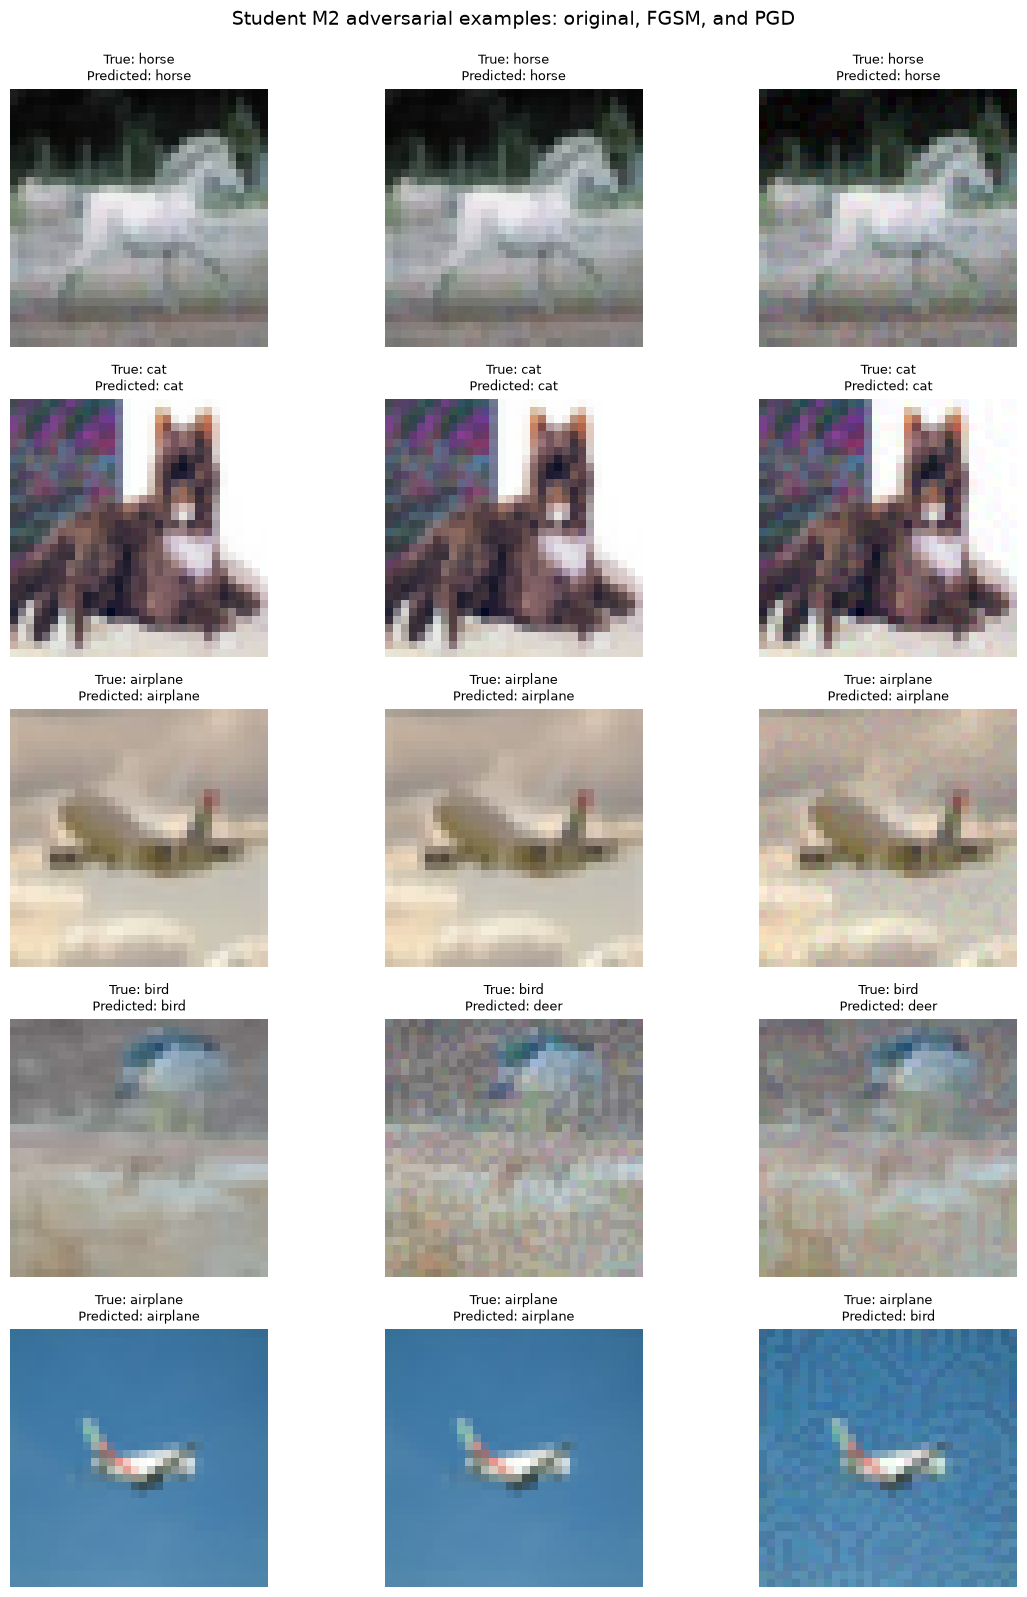

Saved: ATDL_Assignment2_outputs/student_five_adversarial_examples.png


,example,true_label,original_prediction,fgsm_prediction,pgd_prediction
0,1,horse,horse,horse,horse
1,2,cat,cat,cat,cat
2,3,airplane,airplane,airplane,airplane
3,4,bird,bird,deer,deer
4,5,airplane,airplane,airplane,bird


In [13]:
@torch.no_grad()
def collect_clean_correct_examples(model: nn.Module, loader: DataLoader, n_examples: int = 5):
    model.eval()
    selected_images, selected_labels = [], []
    for images, labels in loader:
        images_device = images.to(device, non_blocking=True)
        labels_device = labels.to(device, non_blocking=True)
        predictions = model(images_device).argmax(dim=1)
        correct_mask = (predictions == labels_device).detach().cpu()
        for idx, is_correct in enumerate(correct_mask.tolist()):
            if is_correct:
                selected_images.append(images[idx].clone())  # keep raw CPU image
                selected_labels.append(int(labels[idx]))
                if len(selected_images) == n_examples:
                    return torch.stack(selected_images), torch.tensor(selected_labels, dtype=torch.long), True
    # Fallback if model has fewer than n_examples correct in the selected subset.
    for images, labels in loader:
        for idx in range(images.shape[0]):
            selected_images.append(images[idx].clone())
            selected_labels.append(int(labels[idx]))
            if len(selected_images) == n_examples:
                return torch.stack(selected_images), torch.tensor(selected_labels, dtype=torch.long), False
    raise RuntimeError("Could not collect five evaluation images.")

student.eval()
visual_images_cpu, visual_labels_cpu, all_clean_correct = collect_clean_correct_examples(student, eval_loader, 5)
if all_clean_correct:
    print("Selected five clean-correct Student M2 examples.")
else:
    print("WARNING: Fewer than five clean-correct samples were found; fallback images are shown.")

visual_images = visual_images_cpu.to(device)
visual_labels = visual_labels_cpu.to(device)
eps_visual = 8/255

# Repeatable random start for the displayed PGD examples.
visual_fgsm = fgsm_attack(student, visual_images, visual_labels, eps_visual)
torch.manual_seed(SEED + 8765)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED + 8765)
visual_pgd = pgd_attack(student, visual_images, visual_labels, eps_visual, alpha=PGD_ALPHA, steps=PGD_STEPS, random_start=True)
validate_attack_constraints(visual_images, visual_fgsm, eps_visual)
validate_attack_constraints(visual_images, visual_pgd, eps_visual)

@torch.no_grad()
def get_predictions(model: nn.Module, images: torch.Tensor):
    model.eval()
    return model(images).argmax(dim=1).detach().cpu().tolist()

pred_original = get_predictions(student, visual_images)
pred_fgsm = get_predictions(student, visual_fgsm)
pred_pgd = get_predictions(student, visual_pgd)

fig, axes = plt.subplots(5, 3, figsize=(12, 16))
column_titles = ["Original", "FGSM (ε=8/255)", "PGD (ε=8/255)"]
for col, title in enumerate(column_titles):
    axes[0, col].set_title(title, fontsize=12, fontweight="bold")

images_columns = [visual_images.detach().cpu(), visual_fgsm.detach().cpu(), visual_pgd.detach().cpu()]
pred_columns = [pred_original, pred_fgsm, pred_pgd]
for row in range(5):
    true_name = CLASS_NAMES[int(visual_labels_cpu[row])]
    for col in range(3):
        image_np = images_columns[col][row].permute(1, 2, 0).numpy()
        axes[row, col].imshow(np.clip(image_np, 0, 1))
        predicted_name = CLASS_NAMES[int(pred_columns[col][row])]
        axes[row, col].set_title(f"True: {true_name}\nPredicted: {predicted_name}", fontsize=9)
        axes[row, col].axis("off")
fig.suptitle("Student M2 adversarial examples: original, FGSM, and PGD", y=0.995, fontsize=14)
fig.tight_layout()
visual_grid_path = OUTPUT_DIR / "student_five_adversarial_examples.png"
fig.savefig(visual_grid_path, dpi=180, bbox_inches="tight")
plt.show()
print("Saved:", visual_grid_path)

visual_summary_df = pd.DataFrame({
    "example": range(1, 6),
    "true_label": [CLASS_NAMES[int(x)] for x in visual_labels_cpu.tolist()],
    "original_prediction": [CLASS_NAMES[int(x)] for x in pred_original],
    "fgsm_prediction": [CLASS_NAMES[int(x)] for x in pred_fgsm],
    "pgd_prediction": [CLASS_NAMES[int(x)] for x in pred_pgd],
})
visual_summary_df.to_csv(OUTPUT_DIR / "student_visual_examples_labels.csv", index=False)
display(visual_summary_df)

## 14. Compare FGSM and PGD at ε = 8/255

This comparison is useful for the final discussion, but should be interpreted from your actual results. PGD is iterative and often stronger than single-step FGSM, but the measured ordering depends on the learned models and exact setup.

In [14]:
eps8_rows = adversarial_results_df[adversarial_results_df["epsilon_pixel_levels"] == 8]
attack_comparison_eps8 = eps8_rows.pivot(index="model", columns="attack", values="accuracy_pct")
attack_comparison_eps8 = attack_comparison_eps8[["FGSM", "PGD"]]
attack_comparison_eps8.to_csv(OUTPUT_DIR / "fgsm_vs_pgd_at_epsilon_8_over_255.csv")
print("Accuracy at ε = 8/255 (%):")
display(attack_comparison_eps8.round(2))

Accuracy at ε = 8/255 (%):


attack,FGSM,PGD
model,,
Baseline B,9.3,0.0
Student M2,84.5,79.9
Teacher M1,85.3,82.1


## 15. Final result summary and report-ready export

The following cell saves the required outputs into `ATDL_Assignment2_outputs/`:

- `training_loss_curves.png`
- `clean_accuracy_and_training_time.csv`
- `fgsm_accuracy_table.csv` and `pgd_accuracy_table.csv`
- `fgsm_accuracy_vs_epsilon.png` and `pgd_accuracy_vs_epsilon.png`
- `student_five_adversarial_examples.png` and its label table
- `epsilon_zero_verification.csv`
- raw long-form accuracy data, training history, experiment configuration, and three model checkpoints

The ZIP file contains report artifacts (tables, CSVs, figures and metadata); model checkpoints remain in the separate `checkpoints/` directory because they are large.

In [15]:
# Add clean accuracies and timing to a reproducibility metadata file.
metadata = {
    "experiment_config": CONFIG,
    "device": str(device),
    "gpu_name": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
    "torch_version": torch.__version__,
    "torchvision_version": torchvision.__version__,
    "evaluation_subset_size": len(eval_dataset),
    "clean_accuracy_pct": {k: float(v) for k, v in clean_accuracy.items()},
    "training_seconds": {k: float(v) for k, v in training_seconds.items()},
    "teacher_loss_note": "Teacher trains with T * CE(logits/T, hard labels); explicit documented gradient-scale compensation because the assignment table specifies T=20 but does not give a teacher loss equation.",
    "student_loss": "-T^2 * mean_i sum_k softmax(teacher_logits/T)_k * log_softmax(student_logits/T)_k",
    "attack_loss": "True-label cross entropy on model logits at T=1; perturbations are applied in raw [0,1] pixel space.",
}
with open(OUTPUT_DIR / "experiment_metadata.json", "w") as f:
    json.dump(metadata, f, indent=2)

# Include charts, tables and experiment metadata in a manageable report-artifacts ZIP.
report_zip_path = OUTPUT_DIR / "ATDL_Assignment2_Report_Artifacts.zip"
include_names = [
    "experiment_config.json",
    "experiment_metadata.json",
    "training_loss_history.csv",
    "training_times.csv",
    "clean_accuracy_and_training_time.csv",
    "adversarial_accuracy_long.csv",
    "fgsm_accuracy_table.csv",
    "pgd_accuracy_table.csv",
    "epsilon_zero_verification.csv",
    "student_visual_examples_labels.csv",
    "fgsm_vs_pgd_at_epsilon_8_over_255.csv",
    "training_loss_curves.png",
    "fgsm_accuracy_vs_epsilon.png",
    "pgd_accuracy_vs_epsilon.png",
    "student_five_adversarial_examples.png",
]
with zipfile.ZipFile(report_zip_path, "w", compression=zipfile.ZIP_DEFLATED) as zf:
    for name in include_names:
        file_path = OUTPUT_DIR / name
        if file_path.exists():
            zf.write(file_path, arcname=name)

print("\n=== Main results ===")
display(training_summary_df.round(2))
print("\nFGSM accuracy (%):")
display(fgsm_table.round(2))
print("\nPGD accuracy (%):")
display(pgd_table.round(2))
print("\nReport artifacts ZIP:", report_zip_path)
print("Model checkpoints:")
for path in sorted(CHECKPOINT_DIR.glob("*.pth")):
    print(" -", path, f"({path.stat().st_size / (1024**2):.1f} MiB)")
print("\nWhen running in Colab, use the optional cell below to download the ZIP or copy it to Google Drive.")


=== Main results ===


,model,training_minutes,clean_accuracy_pct
0,Baseline B,21.71,92.65
1,Teacher M1,21.76,92.55
2,Student M2,27.11,92.45



FGSM accuracy (%):


model,Baseline B,Teacher M1,Student M2
Epsilon,,,
0,92.65,92.55,92.45
2/255,26.65,85.35,84.50
4/255,13.25,85.40,84.45
8/255,9.30,85.30,84.50
16/255,8.75,85.65,84.85



PGD accuracy (%):


model,Baseline B,Teacher M1,Student M2
Epsilon,,,
0,92.65,92.55,92.45
2/255,7.20,85.35,84.60
4/255,0.00,84.20,84.25
8/255,0.00,82.10,79.90
16/255,0.00,67.35,63.30



Report artifacts ZIP: ATDL_Assignment2_outputs/ATDL_Assignment2_Report_Artifacts.zip
Model checkpoints:
 - ATDL_Assignment2_outputs/checkpoints/baseline_B_resnet34.pth (81.3 MiB)
 - ATDL_Assignment2_outputs/checkpoints/student_M2_resnet34.pth (81.3 MiB)
 - ATDL_Assignment2_outputs/checkpoints/teacher_M1_resnet34.pth (81.3 MiB)

When running in Colab, use the optional cell below to download the ZIP or copy it to Google Drive.


## 16. Optional: download report artifacts or save them to Google Drive

Run one of the following options only after the notebook finishes.

### Download the report ZIP to your computer
Uncomment and run the code cell below. It downloads figures, tables, and metadata, but not the large checkpoint files.

In [16]:
# OPTIONAL — run in Google Colab to download the report-artifacts ZIP.
# from google.colab import files
# files.download(str(report_zip_path))

### Optional: persist results and checkpoints in Google Drive

Colab's `/content` storage is temporary and can disappear when the runtime resets. Run this optional cell to copy the entire output folder, including checkpoints, into Drive.

In [17]:
# OPTIONAL — mount Drive, then copy outputs (including the three checkpoints).
# from google.colab import drive
# drive.mount('/content/drive')
# drive_destination = Path('/content/drive/MyDrive/ATDL_Assignment2_outputs')
# shutil.copytree(OUTPUT_DIR, drive_destination, dirs_exist_ok=True)
# print('Copied results to:', drive_destination)

## 17. Results and discussion

All three CIFAR-10 ResNet34 models trained for 50 epochs on the full 50,000-image training split using the local NVIDIA RTX 4000 Ada GPU. Evaluation used the same fixed 2,000-image test subset for every clean and adversarial comparison. The training-loss plots, clean-accuracy and training-time table, FGSM/PGD accuracy tables and curves, and five-image student comparison appear above.

### Clean results

| Model | Clean accuracy | Training time |
|---|---:|---:|
| Baseline B | 92.65% | 21.71 min |
| Teacher M1 | 92.55% | 21.76 min |
| Student M2 | 92.45% | 27.11 min |

All six ε=0 checks exactly matched clean accuracy. Compared with the prior 30-epoch run, the student clean accuracy rose from 91.65% to 92.45% (+0.80 percentage points); the baseline rose from 92.35% to 92.65%, and the teacher rose from 90.80% to 92.55%. These are measured outcomes on the fixed subset, not a guarantee of full-test-set performance.

### Adversarial results and conclusion

At ε=8/255, FGSM accuracy was 9.30% for Baseline B, 85.30% for Teacher M1, and 84.50% for Student M2. Under 20-step PGD, the corresponding accuracies were 0.00%, 82.10%, and 79.90%. At ε=16/255 PGD, Teacher M1 retained 67.35% and Student M2 retained 63.30%, while Baseline B fell to 0.00%.

The distilled student showed substantially higher measured adversarial accuracy than the hard-label baseline at each nonzero tested budget, while remaining below its teacher under the larger PGD budgets. FGSM accuracy for the distilled models is slightly non-monotonic across budgets; this reflects the measured results and reinforces that robustness should be interpreted across multiple attack strengths. PGD accuracy declines as ε increases and gives the stronger iterative attack assessment in this experiment.

Smaller input gradients alone do not establish robustness. This notebook assesses robustness through accuracy under the specified, budget-constrained attacks. Flat or non-monotonic results can also indicate limitations of an attack or finite evaluation sample, so attack implementation and perturbation constraints must be checked.

### Limitations

Evaluation uses a fixed 2,000-image test subset rather than the full 10,000-image test set to keep 20-step PGD practical. Models were trained from scratch for 50 epochs with the optimizer and augmentation choices recorded in `experiment_config.json`.
